In [23]:
import os 
import sys 
from pathlib import Path

import tensorflow as tf
import cv2 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
ROOT_DIR = Path('/home/fangyuan/Projects/Diagnostic-des-tumeurs')

VALID_EXTENSIONS = ('.jpeg' , '.jpg' , '.png' , '.bmp' )
IMG_SIZE = (224, 224)
DATA = ROOT_DIR / 'data' / 'archive' / 'Train'
SEED = 42 
BATCH_SIZE = 32 
EPOCHS = 20
LEARNING_RATE = 0.001


In [ ]:
classes = sorted( dir.name for dir in DATA.iterdir() if dir.is_dir() )
class_to_id = { name : id for id, name in enumerate(classes) }

In [17]:
paths, labels = [], [] 


for class_name in classes : 
    class_dir = DATA / class_name / 'images'  
    for file in class_dir.iterdir() : 
        if file.suffix.lower() in VALID_EXTENSIONS : 
            paths.append(file) 
            labels.append(class_to_id[class_name])


In [22]:
def load_image(path, label) : 
    try : 
        image = cv2.imread(str(path))

        if image is None : 
            raise FileNotFoundError(f"Image not found or cannot be read: {path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMG_SIZE) 

        return image, label 

    except cv2.error as e : 
        print(f"Error reading image {path}: {e}")
        return None, None

    except FileNotFoundError as e : 
        print(e)
        return None, None

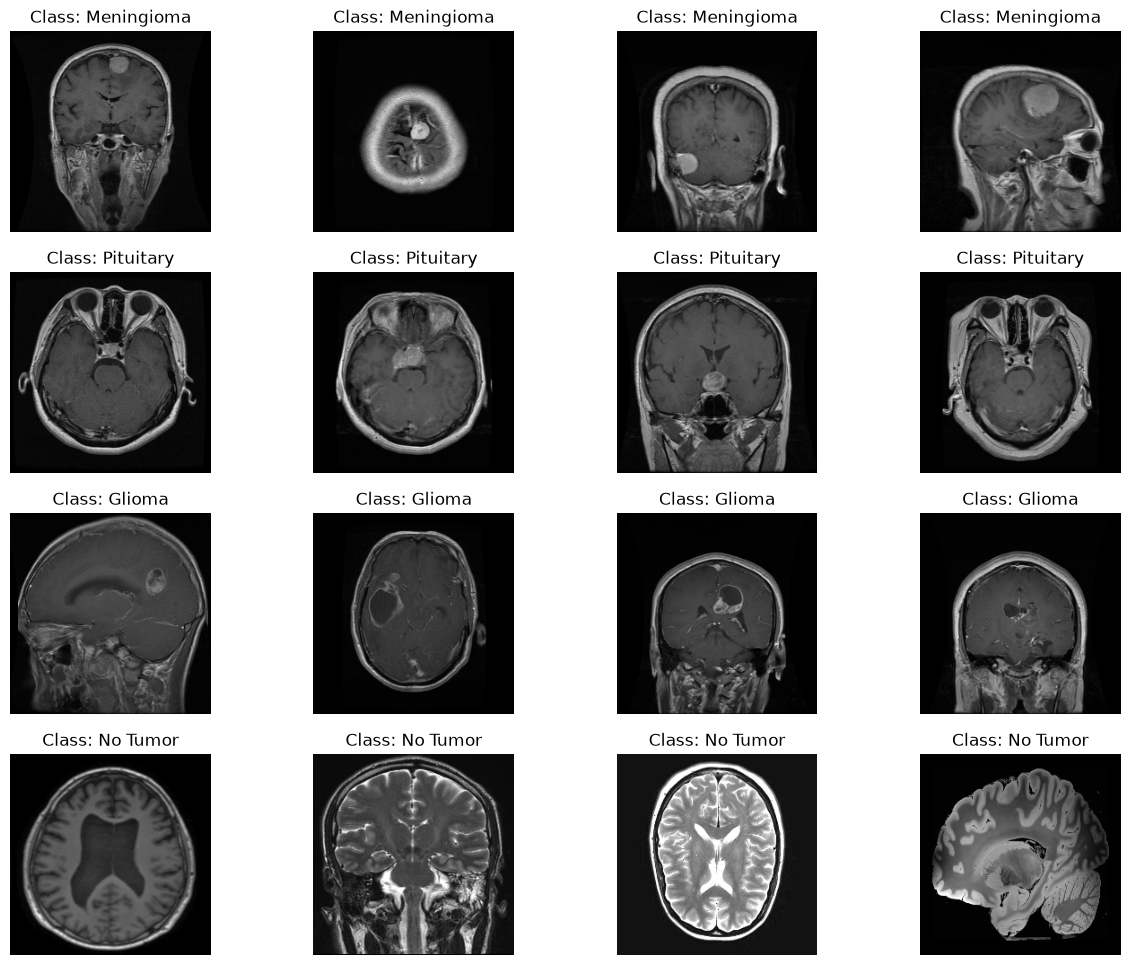

In [31]:
fig , axes = plt.subplots(4, 4, figsize=(15, 12))

for id , label in enumerate(pd.Series(labels).value_counts().index) :
    label_images = [paths[j] for j in range(len(labels)) if labels[j] == label]

    for i in range(4) : 
        image, _ = load_image(label_images[i], label)
        if image is not None : 
            axes[id, i].imshow(image)
            axes[id, i].set_title(f"Class: {classes[label]}")
            axes[id, i].axis('off')

